# 06 - SHAP explanations and business rules
Explain the final XGBoost churn model with SHAP, show a readable CART tree, turn predictions into actions, and backtest campaign strategies on the TEST snapshot.

In [1]:
import sys
sys.path.append('../src')

import json
import numpy as np
import pandas as pd
import config
import explain as ex
import decision_rules as dr

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 200)

train = pd.read_parquet(config.TRAIN_TABLE_PARQUET)
test = pd.read_parquet(config.TEST_TABLE_PARQUET)
bundle, encoder = ex.load_churn_parts()
print('Churn model:', bundle['name'])
print('Features:', ex.plain_names(bundle['features']))

D:\SEM-7\churn-clv-predictor\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Churn model: XGBoost | none
Features: ['Number of orders', 'Total spent (GBP)', 'Variation in days between orders', 'Days since first order', 'Days since last order', 'In Champions segment', 'Different products bought', 'Share of spend in last 3 months']


## 1. Global SHAP summary
SHAP values are in log-odds: right of 0 = pushes churn risk up, left = pushes it down. Computed on a random sample of test customers (to save memory). Colours show the REAL feature value (red = high).

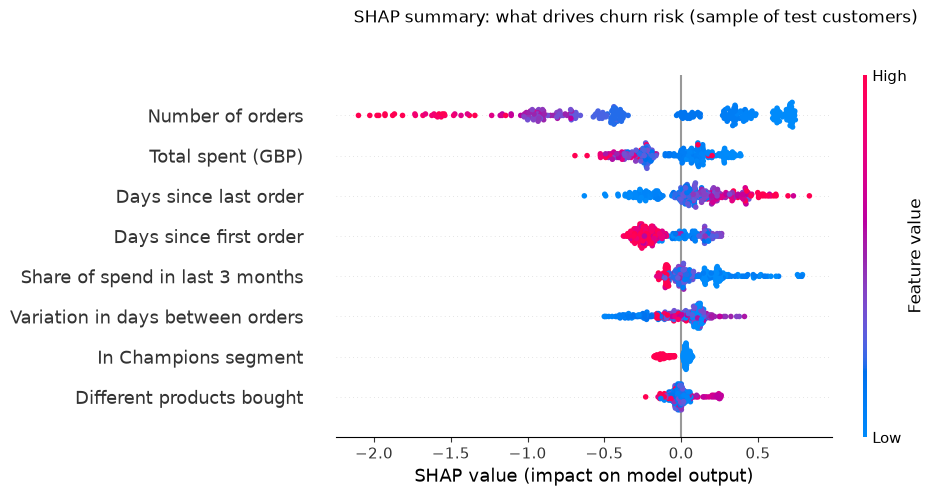

In [2]:
sample = test.sample(config.SHAP_SAMPLE_SIZE, random_state=config.RANDOM_STATE)
explanation = ex.shap_explanation(sample, bundle, encoder)
ex.plot_shap_summary(explanation);

In [3]:
importance = pd.Series(np.abs(explanation.values).mean(axis=0), index=explanation.feature_names)
importance.sort_values(ascending=False).round(3).rename('mean |SHAP| (log-odds)')

Number of orders                    0.672
Total spent (GBP)                   0.220
Days since last order               0.215
Days since first order              0.191
Share of spend in last 3 months     0.148
Variation in days between orders    0.142
In Champions segment                0.057
Different products bought           0.052
Name: mean |SHAP| (log-odds), dtype: float32

**What drives churn risk:** **Number of orders** matters most by far (mean |SHAP| 0.67 log-odds): customers with many orders (red) get a strongly lower risk, customers with 1-2 orders (blue) a higher one. Next come total spent (0.22), days since last order (0.22; long gaps raise risk), days since first order (0.19; long-standing customers are safer) and share of spend in the last 3 months (0.15; a low recent share raises risk). Being a Champion and the number of different products add little (about 0.05 each), which matches Phase 4: the segment adds little beyond RFM.

## 2. Two example customers

In [4]:
probabilities = bundle['model'].predict_proba(ex.model_inputs(sample, bundle, encoder))[:, 1]
high_idx, low_idx = int(np.argmax(probabilities)), int(np.argmin(probabilities))
for label, idx in [('HIGH risk', high_idx), ('LOW risk', low_idx)]:
    customer = sample.iloc[[idx]]
    probability, sentences = ex.explain_customer(customer, bundle, encoder)
    print(f'{label}: customer {customer.index[0]}, segment {customer["segment_name"].iloc[0]}, '
          f'churn probability {probability:.0%}, actually churned: {bool(customer["churn"].iloc[0])}')
    for sentence in sentences:
        print('   ', sentence)

HIGH risk: customer 15545, segment At-Risk, churn probability 93%, actually churned: True
    179 days since last order -> raises risk
    1 order in total -> raises risk
    135 GBP spent in total -> raises risk
    0% of spend in the last 3 months -> raises risk
LOW risk: customer 15311, segment Champions, churn probability 3%, actually churned: False
    159 orders in total -> lowers risk
    83,591 GBP spent in total -> lowers risk
    4 days since last order -> lowers risk
    gaps between orders vary by about 3 days -> lowers risk


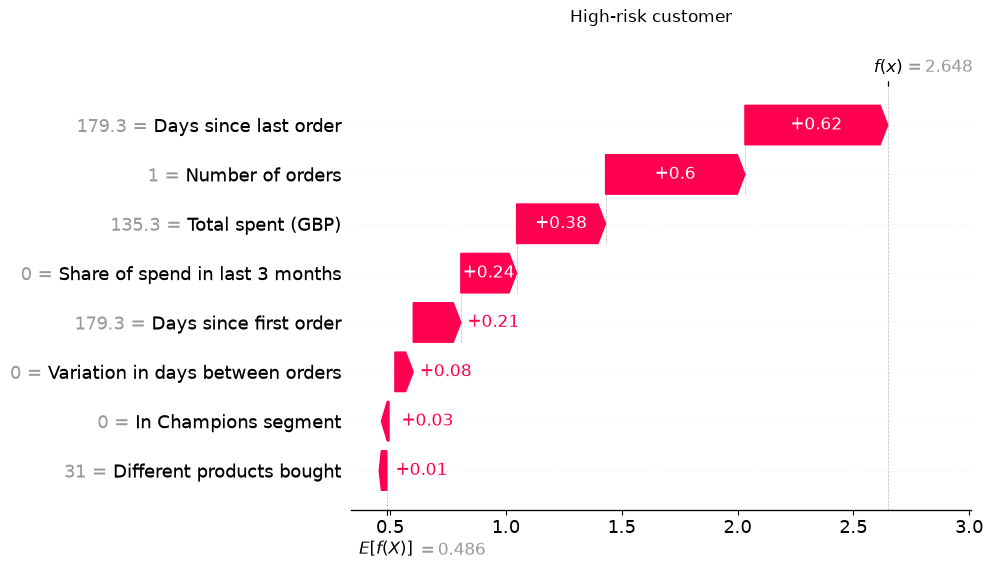

In [5]:
ex.plot_shap_waterfall(explanation, high_idx, 'shap_waterfall_high_risk', 'High-risk customer');

In [6]:
ex.plot_shap_waterfall(explanation, low_idx, 'shap_waterfall_low_risk', 'Low-risk customer');

**High-risk example** (customer 15545, At-Risk, 93%, really churned): one order, 179 days ago, 135 GBP in total, nothing in the last 3 months - every main factor pushes the risk up. **Low-risk example** (customer 15311, Champion, 3%, did not churn): 159 orders, about 83,600 GBP spent, last order 4 days ago, very regular gaps - every main factor pushes the risk down. The waterfall plots are in log-odds: they start at the average model output (0.486 log-odds) and add each feature's push to reach the customer's score.

## 3. CART rules (readable baseline)
A depth-3 tree on the same 8 features, with real (not log) values so the thresholds are readable.

In [7]:
rules, cart_auc = ex.cart_rules(train, test, bundle['features'])
ex.save_cart_rules(rules, cart_auc)
print(f'Test ROC-AUC of this small tree: {cart_auc:.3f}\n')
print(rules)

Test ROC-AUC of this small tree: 0.735

|--- Number of orders <= 4.5
|   |--- Variation in days between orders <= 0.5
|   |   |--- Days since last order <= 57.5
|   |   |   |--- weights: [214.0, 696.0] class: churns
|   |   |--- Days since last order >  57.5
|   |   |   |--- weights: [82.0, 569.0] class: churns
|   |--- Variation in days between orders >  0.5
|   |   |--- Days since first order <= 156.4
|   |   |   |--- weights: [84.0, 71.0] class: stays
|   |   |--- Days since first order >  156.4
|   |   |   |--- weights: [202.0, 457.0] class: churns
|--- Number of orders >  4.5
|   |--- In Champions segment <= 0.5
|   |   |--- Variation in days between orders <= 33.2
|   |   |   |--- weights: [155.0, 92.0] class: stays
|   |   |--- Variation in days between orders >  33.2
|   |   |   |--- weights: [160.0, 163.0] class: churns
|   |--- In Champions segment >  0.5
|   |   |--- Share of spend in last 3 months <= 0.1
|   |   |   |--- weights: [12.0, 19.0] class: churns
|   |   |--- Shar

**Readable rules:** The first split is **number of orders <= 4.5**. Customers with few orders mostly churn (for example, 696 of 910 customers with few orders and no variation in gaps, i.e. 1-2 orders, churned even when their last order was recent). Among customers with more orders, Champions who still spent recently mostly stay (409 stay vs 80 churn). This small tree reaches test ROC-AUC 0.735, below XGBoost's 0.762 but easy to explain in a viva.

## 4. From predictions to actions
### Which value goes into the profit rule?
The spend model gives two numbers:
- **conditional amount** = what the customer would spend in 6 months *if they stay and buy* (part 2 of the spend model);
- **expected spend** = P(spend > 0) x conditional amount.

The profit rule uses the **conditional amount**. If we used expected spend, churn would be counted twice: a likely churner already has a low P(spend > 0), so their value would be shrunk once by the spend model and again by the churn probability. Expected spend is still used for display and for the high/low **value** split in the action matrix.

### The profit rule, term by term
The offer is a **discount**. Its real cost is not the email, it is the discount, and customers who would have stayed anyway use it too.

`expected_net = p x response_rate x amount x (margin - discount)  -  (1 - p) x redeem_rate x discount x amount  -  contact_cost`

- **Gain from kept churners:** with probability `p` the customer would leave. The offer keeps `response_rate` of those. A kept customer spends `amount`, and we earn the margin minus the discount we gave on it.
- **Discount wasted on stayers:** with probability `1 - p` the customer would have stayed anyway. They still use the discount (`redeem_rate`, worst case 100%), so we lose `discount x amount` for nothing.
- **Contact cost:** a small fixed cost per customer contacted.

Send the offer only if `expected_net > 0`.

**ASSUMPTIONS (not from data):** gross margin 30%, discount 10%, contact cost 1 GBP, response rate 20%, stayer redeem rate 100%.

In [8]:
print(json.dumps(dr.default_assumptions(), indent=2))
train_scores = dr.score_customers(train)
thresholds = dr.fit_split_points(train_scores)
{k: thresholds[k] for k in ['risk_threshold', 'value_threshold', 'split_rule']}

{
  "response_rate": 0.2,
  "discount_rate": 0.1,
  "gross_margin": 0.3,
  "contact_cost": 1.0,
  "stayer_redeem_rate": 1.0
}


{'risk_threshold': 0.689228355884552,
 'value_threshold': 349.97536538195817,
 'split_rule': 'medians of TRAIN churn probability and TRAIN expected spend'}

**Split points (from TRAIN only, saved in `models/decision_thresholds.json` together with the profit-rule assumptions):** high risk = churn probability >= **68.9%** (TRAIN median); high value = expected 6-month spend >= **350 GBP** (TRAIN median). Because the TRAIN churn rate was 0.62 and TEST is 0.50, fewer TEST customers fall above the risk split.

In [9]:
test_scores = dr.add_actions(dr.score_customers(test), thresholds)
print(f"Mean predicted churn probability on TEST: {test_scores['churn_probability'].mean():.3f}   "
      f"actual TEST churn rate: {test['churn'].mean():.3f}")
print(f"Customers passing the profit rule: {(test_scores['expected_net'] > 0).sum():,} of {len(test_scores):,}")
pd.crosstab(test_scores['segment_name'], test_scores['action'], margins=True)

Mean predicted churn probability on TEST: 0.550   actual TEST churn rate: 0.500
Customers passing the profit rule: 809 of 2,658


action,Keep happy: loyalty perks,Low-cost email only,No action,Retention offer (priority),All
segment_name,,,,,
At-Risk,137,362,75,47,621
Champions,704,0,0,1,705
Loyal,563,57,189,16,825
One-off buyers,8,437,30,32,507
All,1412,856,294,96,2658


In [10]:
for customer_id in test_scores.index[:3]:
    r = test_scores.loc[customer_id]
    print(customer_id, '->', r['action'])
    print('   ', r['reason'])

12346 -> Keep happy: loyalty perks
    Champions (top customer: best handled with a personal contact). Churn risk 68.6% is low (split 68.9%); expected 6-month spend 18,958 GBP is HIGH (split 350 GBP). Expected net profit of a 10% discount offer: -91 GBP -> profit rule fails.
12347 -> Keep happy: loyalty perks
    Loyal (regular buyer: a reminder or small incentive fits). Churn risk 59.0% is low (split 68.9%); expected 6-month spend 942 GBP is HIGH (split 350 GBP). Expected net profit of a 10% discount offer: -25 GBP -> profit rule fails.
12348 -> Keep happy: loyalty perks
    Loyal (regular buyer: a reminder or small incentive fits). Churn risk 65.0% is low (split 68.9%); expected 6-month spend 575 GBP is HIGH (split 350 GBP). Expected net profit of a 10% discount offer: -9 GBP -> profit rule fails.


**Actions on TEST:** 809 of 2,658 customers pass the new profit rule. With 10% discount and 20% response, the rule only pays when churn probability is above about 72%: below that, the discount wasted on likely stayers outweighs the margin from the few churners kept. In the action matrix, **96 customers get 'Retention offer (priority)'** (47 At-Risk, 32 One-off buyers, 16 Loyal, 1 Champion), 1,412 'Keep happy: loyalty perks' (almost all Champions and most Loyal), 856 'Low-cost email only' and 294 'No action'. Champions almost never get a discount: their churn risk is low, so most of the discount would go to customers who stay anyway.

## 5. Backtest on TEST (actual labels)
For every contacted customer we use what really happened:
- **actual churner:** + response_rate x predicted amount x (margin - discount)
- **actual non-churner:** - redeem_rate x discount x their ACTUAL future spend (wasted discount)
- **everyone contacted:** - contact cost

Same ASSUMPTIONS as above. Note: churn probabilities run about 5 points high on TEST (0.55 predicted vs 0.50 actual).

In [11]:
impact = dr.backtest(test_scores, test['churn'], test['future_spend'], thresholds)
impact.to_csv(config.TABLES_DIR / 'business_impact_test.csv', index=False)
impact.round(1)

,strategy,contacted,churners_reached,share_of_all_churners,stayers_contacted,gain_from_kept_churners,wasted_discount_cost,contact_cost,net_profit
0,(a) Mail everyone,2658,1330,1.0,1328,44400.6,348394.0,2658.0,-306651.3
1,(b) Top 20% highest churn risk,532,408,0.3,124,8278.6,8704.3,532.0,-957.7
2,(c) Profit rule (expected_net > 0),809,596,0.4,213,12998.3,20474.1,809.0,-8284.8
3,(d) Priority offers only,96,64,0.0,32,3397.7,9018.8,96.0,-5717.1
4,(e) No campaign,0,0,0.0,0,0.0,0.0,0.0,0.0


In [12]:
dr.plot_headline(impact);

**Backtest at the default assumptions (10% discount, 20% response): no campaign wins.** Every strategy loses money: mailing everyone -306,651 GBP (348,394 GBP of discount wasted on 1,328 stayers), profit rule -8,285 GBP (809 contacted, 596 churners reached), priority offers -5,717 GBP, top 20% by risk -958 GBP. The problem is the worst-case assumption that every stayer redeems a 10% discount on all their future spend: the gain from a kept churner (20% x 20% net margin = 4% of their amount) is small compared with 10% of a stayer's spend.

The headline chart shows the same numbers: mailing everyone would lose about 307,000 GBP; every model-based strategy keeps the loss under about 8,300 GBP, so targeting avoids about 97% or more of that loss.

### Why does the profit rule lose money on TEST?

In [13]:
picked = test_scores['expected_net'] > 0
stayed = picked & (test['churn'] == 0)
print(f"Profit rule picks {picked.sum()} customers; it EXPECTED a total net of {test_scores.loc[picked, 'expected_net'].sum():,.0f} GBP")
print(f"  mean predicted churn probability {test_scores.loc[picked, 'churn_probability'].mean():.3f} "
      f"vs actual churn rate {test.loc[picked, 'churn'].mean():.3f}")
print(f"  stayers: mean predicted amount {test_scores.loc[stayed, 'conditional_amount'].mean():,.0f} GBP "
      f"vs mean ACTUAL spend {test.loc[stayed, 'future_spend'].mean():,.0f} GBP")

Profit rule picks 809 customers; it EXPECTED a total net of 5,956 GBP
  mean predicted churn probability 0.828 vs actual churn rate 0.737
  stayers: mean predicted amount 632 GBP vs mean ACTUAL spend 961 GBP


**Why the profit rule loses on TEST:** it expected +5,956 GBP for its 809 customers but got -8,285 GBP. Two reasons, both known issues: (1) churn probabilities are too high: the picked customers have a mean predicted churn probability of 0.828 but only 0.737 really churned, so more discounts went to stayers than expected; (2) stayers spent more than predicted (961 GBP actual vs 632 GBP predicted on average, the season mismatch), so each wasted discount cost more. The rule is only as good as the probabilities and amounts it is given.

### Sensitivity: response rate x discount rate x stayer redeem rate (net profit in GBP)
The defaults are NOT changed; this only shows how the answer depends on the assumptions. The profit rule and the priority offers are re-decided for every combination.

In [14]:
sens = dr.sensitivity(test_scores, test['churn'], test['future_spend'], thresholds)
sens.to_csv(config.TABLES_DIR / 'business_impact_sensitivity.csv', index=False)
sens.pivot_table(index=['stayer_redeem_rate', 'discount_rate', 'response_rate'], columns='strategy', values='net_profit').round(0)

strategy                                        (a) Mail everyone  (b) Top 20% highest churn risk  (c) Profit rule (expected_net > 0)  (d) Priority offers only  (e) No campaign
stayer_redeem_rate discount_rate response_rate                                                                                                                                  
0.3                0.05          0.05                    -41042.0                           749.0                                86.0                    -756.0              0.0
                                 0.10                    -27167.0                          3336.0                              8864.0                     476.0              0.0
                                 0.20                       584.0                          8511.0                             31963.0                    2939.0              0.0
                                 0.30                     28334.0                         13685.0                             56744.0                    5402.0              0.0
                   0.10          0.05                    -96076.0                         -1074.0                             -2796.0                   -1855.0              0.0
                                 0.10                    -84976.0                           996.0                             -1645.0                   -1875.0              0.0
                                 0.20                    -62776.0                          5135.0                             11158.0                      96.0              0.0
                                 0.30                    -40575.0                          9275.0                             28453.0                    2066.0              0.0
                   0.20          0.05                   -206144.0                         -4720.0                                 0.0                       0.0              0.0
                                 0.10                   -200594.0                         -3685.0                              -268.0                      39.0              0.0
                                 0.20                   -189494.0                         -1615.0                             -5121.0                   -3632.0              0.0
                                 0.30                   -178394.0                           454.0                             -4753.0                   -4606.0              0.0
0.5                0.05          0.05                    -75881.0                          -121.0                             -2254.0                   -1926.0              0.0
                                 0.10                    -62006.0                          2466.0                              3110.0                    -763.0              0.0
                                 0.20                    -34256.0                          7640.0                             23285.0                    1700.0              0.0
                                 0.30                     -6505.0                         12814.0                             45965.0                    4164.0              0.0
                   0.10          0.05                   -165755.0                         -2814.0                              -475.0                     -29.0              0.0
                                 0.10                   -154655.0                          -745.0                             -4353.0                   -2971.0              0.0
                                 0.20                   -132454.0                          3394.0                              1299.0                   -2382.0              0.0
                                 0.30                   -110254.0                          7534.0                             14848.0                    -411.0              0.0
                   0.20          0.05                   -345502.0                         -8201.0         

In [15]:
best = dr.best_strategy_per_combination(sens)
best.to_csv(config.TABLES_DIR / 'business_best_strategy_per_assumption.csv', index=False)
best.round(2)

,stayer_redeem_rate,discount_rate,response_rate,strategy,contacted,net_profit
0,0.3,0.05,0.05,(b) Top 20% highest churn risk,532,749.41
1,0.3,0.05,0.10,(c) Profit rule (expected_net > 0),1906,8863.87
2,0.3,0.05,0.20,(c) Profit rule (expected_net > 0),2288,31962.78
3,0.3,0.05,0.30,(c) Profit rule (expected_net > 0),2383,56743.90
4,0.3,0.10,0.05,(e) No campaign,0,0.00
5,0.3,0.10,0.10,(b) Top 20% highest churn risk,532,996.00
6,0.3,0.10,0.20,(c) Profit rule (expected_net > 0),1737,11158.30
7,0.3,0.10,0.30,(c) Profit rule (expected_net > 0),2065,28452.56
8,0.3,0.20,0.05,(e) No campaign,0,0.00
9,0.3,0.20,0.10,(d) Priority offers only,8,39.07


In [16]:
best['strategy'].value_counts()

strategy
(e) No campaign                       17
(c) Profit rule (expected_net > 0)    11
(b) Top 20% highest churn risk         6
(d) Priority offers only               2
Name: count, dtype: int64

In [17]:
best.pivot_table(index=['stayer_redeem_rate', 'discount_rate'], columns='response_rate', values='strategy', aggfunc='first')

response_rate                                               0.05                                0.10                                0.20                                0.30
stayer_redeem_rate discount_rate                                                                                                                                            
0.3                0.05           (b) Top 20% highest churn risk  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)
                   0.10                          (e) No campaign      (b) Top 20% highest churn risk  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)
                   0.20                          (e) No campaign            (d) Priority offers only                     (e) No campaign      (b) Top 20% highest churn risk
0.5                0.05                          (e) No campaign  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)
                   0.10                          (e) No campaign                     (e) No campaign      (b) Top 20% highest churn risk  (c) Profit rule (expected_net > 0)
                   0.20                          (e) No campaign                     (e) No campaign                     (e) No campaign                     (e) No campaign
1.0                0.05                          (e) No campaign      (b) Top 20% highest churn risk  (c) Profit rule (expected_net > 0)  (c) Profit rule (expected_net > 0)
                   0.10                          (e) No campaign                     (e) No campaign                     (e) No campaign      (b) Top 20% highest churn risk
                   0.20                          (e) No campaign                     (e) No campaign                     (e) No campaign            (d) Priority offers only

**Sensitivity (36 combinations of stayer redeem rate x discount x response rate; defaults unchanged):** 'No campaign' is best in **17** combinations, the profit rule in **11**, top 20% by risk in **6**, priority offers in **2** (by tiny amounts, 39 and 58 GBP). The profit rule wins whenever the discount is small (5%) and at least 10-20% of churners respond, and also at 10% discount when few stayers redeem (30-50%) and response is high; its best result is +56,744 GBP (30% redeem, 5% discount, 30% response). With a 20% discount almost nothing pays. Mailing everyone **never** wins: it is positive in only 2 of 36 cases (30% redeem, 5% discount, 20-30% response: +584 / +28,334 GBP) and loses up to 693,896 GBP. **Honest conclusion:** a discount campaign only pays when the discount is small and the offer really convinces churners; a lower stayer redeem rate helps a lot. Otherwise the best decision is not to run a campaign, and the system can show that.

## 6. Priority list: top 50 customers to contact first (TEST snapshot)
Retention offers first (they pass the profit rule), then the remaining customers by expected net profit.

In [18]:
priority = dr.priority_list(test_scores)
priority.to_csv(config.TABLES_DIR / 'priority_list_top50.csv')
priority.drop(columns=['reason']).head(15)

,segment_name,churn_probability,conditional_amount,expected_spend,expected_net,action
customer_id,,,,,,
14088,Loyal,0.771,7567.0,6075.0,58.7,Retention offer (priority)
12764,At-Risk,0.866,2078.0,747.0,43.1,Retention offer (priority)
13328,At-Risk,0.885,1809.0,608.0,42.3,Retention offer (priority)
15171,At-Risk,0.862,1921.0,619.0,38.8,Retention offer (priority)
14411,At-Risk,0.887,1555.0,504.0,36.6,Retention offer (priority)
14737,At-Risk,0.837,2129.0,1070.0,35.5,Retention offer (priority)
16152,One-off buyers,0.817,2423.0,925.0,33.7,Retention offer (priority)
13893,At-Risk,0.894,1234.0,389.0,30.1,Retention offer (priority)
16951,At-Risk,0.873,1370.0,461.0,29.5,Retention offer (priority)


In [19]:
print(priority['action'].value_counts())
priority['segment_name'].value_counts()

action
Retention offer (priority)    50
Name: count, dtype: int64


segment_name
At-Risk           25
One-off buyers    24
Loyal              1
Name: count, dtype: int64

**Priority list:** all top-50 customers get 'Retention offer (priority)', ranked by expected net profit (highest 58.7 GBP, for a Loyal customer with 77% risk and 7,567 GBP conditional amount). They are mostly At-Risk (25) and One-off buyers (24), plus 1 Loyal. Remember that the backtest shows these expected profits were too optimistic on TEST.